# Judge analysis of the tune grid

Completeness and groundedness of the `summary` and `eligibility_summary` fields, as scored by an LLM judge.

In [1]:
import os
import random
from pathlib import Path

# Paths below are relative to the repo root.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
REPO_ROOT = Path.cwd()
assert (REPO_ROOT / "pyproject.toml").is_file(), f"unexpected cwd: {REPO_ROOT}"

import matplotlib.pyplot as plt
import pandas as pd

from grant_eval.config import MODEL_ROUTING
from grant_eval.dataset.registry import DEFAULT_REGISTRY_PATH, DEFAULT_SNAPSHOT_ROOT, load_registry
from grant_eval.scoring import judge as judgemod
from grant_eval.scoring import judge_agreement as ja
from grant_eval.scoring import judge_notebook as jn
from grant_eval.scoring.groundtruth import DEFAULT_GROUND_TRUTH_DIR, load_ground_truth

# Same style as analysis/figures.py: matplotlib defaults, tab10, one colour per model.
plt.rcParams.update({"figure.dpi": 110})
PALETTE = plt.get_cmap("tab10")
SERIES = [PALETTE(i) for i in range(10)]
#: Same mapping as figures._draw_f1_by_config: nova-lite=blue, deepseek=orange, gpt-oss=green.
MODEL_COLORS = {
    "nova-lite-v1": PALETTE(0),
    "deepseek-v4-flash-0731": PALETTE(1),
    "gpt-oss-120b": PALETTE(2),
}


def model_color(label):
    """tab10 colour for whichever model `label` names, grey if it names none."""
    for slug, color in MODEL_COLORS.items():
        if slug in label:
            return color
    return "gray"


def short_label(label):
    """`label` without the routing prefix, matching `figures._short_config_label`."""
    model, sep, rest = label.partition(" | ")
    return f"{model.rsplit('/', 1)[-1]} | {rest}" if sep else model.rsplit("/", 1)[-1]

FIELD_DIM_ORDER = [f"{f}:{d}" for f in judgemod.JUDGED_FIELDS for d in judgemod.DIMENSIONS]
GRID_ROOT = REPO_ROOT / "eval" / "final_grid" / "grid"
#: Where the real judge pass wrote its output (the module default is empty).
RESULTS_ROOT = REPO_ROOT / "eval" / "judge_results"
print(f"repo root   : {REPO_ROOT}")
print(f"grid corpus : {GRID_ROOT}")
print(f"judge output: {RESULTS_ROOT}")

repo root   : /home/finn-rea/Developer/msc-code
grid corpus : /home/finn-rea/Developer/msc-code/eval/final_grid/grid
judge output: /home/finn-rea/Developer/msc-code/eval/judge_results


## Provenance

In [2]:
# Built from the module constants, the same way judge.py's CLI does it.
judge_config = judgemod.JudgeConfig(
    model=judgemod.JUDGE_MODEL, temperature=0.0,
    prompt_version=judgemod.PROMPT_VERSION, rubric_version=judgemod.RUBRIC_VERSION,
)
rollup_out_path = judgemod.rollup_path(judge_config.config_hash, root=RESULTS_ROOT)
assert rollup_out_path.is_file(), (
    f"no roll-up at {rollup_out_path}.\n"
    "Either the corpus has not been judged under this judge config, or the judge "
    "config has changed since it was (model / temperature / prompt_version / "
    "rubric_version). Re-run:\n"
    "    uv run judge eval/final_grid/grid/ --results-root eval/judge_results"
)

rollup = judgemod.read_verdict_file(rollup_out_path)
verdict_paths = sorted(RESULTS_ROOT.glob(f"*/*/*/{judge_config.config_hash}.json"))
arms = sorted({p.parts[-4] for p in verdict_paths})
funders = sorted({p.parts[-3] for p in verdict_paths})
replicates = sorted({p.parts[-2] for p in verdict_paths})

print(f"judge config hash : {judge_config.config_hash}")
print(f"roll-up file      : {rollup_out_path.name}")
print(f"runs in roll-up   : {rollup['n_runs']}")
print(f"verdict files     : {len(verdict_paths)}")
print()
print(f"grid arms         : {len(arms)}  (model x prompt strategy x temperature)")
print(f"funders           : {len(funders)}")
print(f"replicates        : {', '.join(replicates)}")

judge config hash : 17fb8f1bc516e87749f31b1c17dd772bd675dc99b9e6ea3c77ecb4f0636663a1
roll-up file      : rollup-17fb8f1bc516e87749f31b1c17dd772bd675dc99b9e6ea3c77ecb4f0636663a1.json
runs in roll-up   : 1920
verdict files     : 1920

grid arms         : 24  (model x prompt strategy x temperature)
funders           : 16
replicates        : 1, 2, 3, 4, 5


## Judge setup

In [3]:
print("judged fields     :", ", ".join(judgemod.JUDGED_FIELDS))
print("NOT judged        : discipline_tags (a tag is a classification, not a claim)")
print("dimensions        :", ", ".join(judgemod.DIMENSIONS))
print("claim type vocab  :", ", ".join(judgemod.CLAIM_TYPES))
print()
print("judge model       :", judge_config.model)
print("provider pin      :", MODEL_ROUTING["gemini-judge"]["provider"])
print("temperature       :", judge_config.temperature)
print("prompt version    :", judge_config.prompt_version)
print("rubric version    :", judge_config.rubric_version)
print("-> config hash    :", judge_config.config_hash)
print()
print("verdict path shape: <run_config_hash>/<funder_slug>/<replicate>/<judge_config_hash>.json")
print("default root      :", judgemod.JUDGE_RESULTS_ROOT, "(unused by this pass)")
print("this pass's root  :", RESULTS_ROOT)

judged fields     : summary, eligibility_summary
NOT judged        : discipline_tags (a tag is a classification, not a claim)
dimensions        : completeness, groundedness
claim type vocab  : eligibility, deadline, amount, purpose, process, other

judge model       : openrouter/google/gemini-2.5-flash-lite
provider pin      : {'only': ['google-ai-studio'], 'allow_fallbacks': False}
temperature       : 0.0
prompt version    : v1
rubric version    : v1
-> config hash    : 17fb8f1bc516e87749f31b1c17dd772bd675dc99b9e6ea3c77ecb4f0636663a1

verdict path shape: <run_config_hash>/<funder_slug>/<replicate>/<judge_config_hash>.json
default root      : eval/results/phase1/judge (unused by this pass)
this pass's root  : /home/finn-rea/Developer/msc-code/eval/judge_results


## Claim-level and record-level rates by field and dimension

In [4]:
def rate_or_undefined(cell, key):
    return "undefined" if cell[f"{key}_undefined"] else round(cell[key], 3)


rates_df = pd.DataFrame([
    {
        "field:dimension": key,
        "n_claims": cell["n_claims"], "n_records_judged": cell["n_records_judged"],
        "claim_rate (micro)": rate_or_undefined(cell, "claim_rate"),
        "claim_rate (macro)": rate_or_undefined(cell, "claim_rate_macro"),
        "record_rate": rate_or_undefined(cell, "record_rate"),
        "n_raw_html_fallback": cell["n_raw_html_fallback"],
    }
    for key, cell in sorted(rollup["fields"].items())
]).set_index("field:dimension").loc[FIELD_DIM_ORDER]
rates_df

,n_claims,n_records_judged,claim_rate (micro),claim_rate (macro),record_rate,n_raw_html_fallback
field:dimension,,,,,,
summary:completeness,33989,5058,0.654,0.652,0.181,0
summary:groundedness,68522,6192,0.989,0.980,0.938,0
eligibility_summary:completeness,37887,4786,0.481,0.503,0.045,0
eligibility_summary:groundedness,25042,5965,0.968,0.970,0.934,0


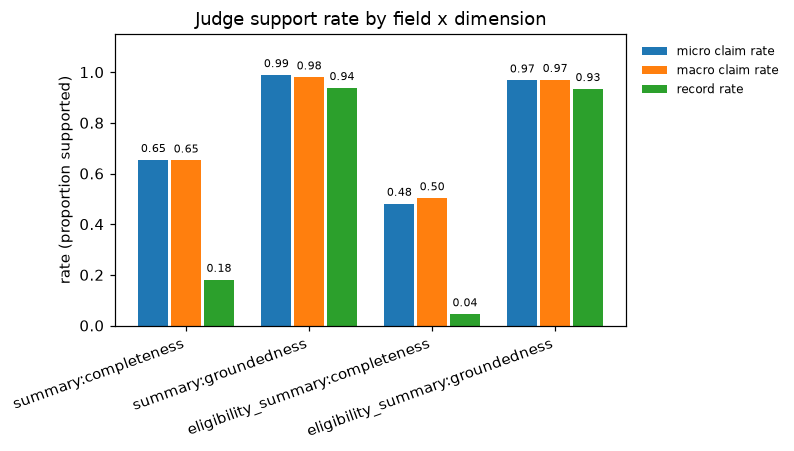

In [5]:
def labelled_group_bar(ax, categories, series, *, ylabel, title, ylim=None):
    '''Grouped bars in the tab10 series colours `figures.py` uses, each bar
    value-labelled; an undefined series entry is rendered as a text label at the
    axis midpoint instead of a bar, so it is never mistaken for a real 0.0.'''
    n_series = len(series)
    width = 0.8 / n_series
    x = range(len(categories))
    for i, (name, values) in enumerate(series.items()):
        offsets = [xi + (i - (n_series - 1) / 2) * width for xi in x]
        labelled = False
        for xo, v in zip(offsets, values):
            if v == "undefined":
                ax.text(xo, 0.5, "undefined", rotation=90, ha="center", va="center", fontsize=8, color="#b03030")
            else:
                ax.bar(xo, v, width=width * 0.92, color=SERIES[i % len(SERIES)],
                       label=None if labelled else name)
                labelled = True
                ax.text(xo, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=7.5)
    ax.set_xticks(list(x))
    ax.set_xticklabels(categories, rotation=20, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if ylim:
        ax.set_ylim(*ylim)
    ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))


fig, ax = plt.subplots(figsize=(7.2, 4.2))
labelled_group_bar(
    ax, rates_df.index.tolist(),
    {
        "micro claim rate": rates_df["claim_rate (micro)"].tolist(),
        "macro claim rate": rates_df["claim_rate (macro)"].tolist(),
        "record rate": rates_df["record_rate"].tolist(),
    },
    ylabel="rate (proportion supported)", title="Judge support rate by field x dimension", ylim=(0, 1.15),
)
fig.tight_layout()
plt.show()

## Rates by model, prompt strategy and temperature

1920 run verdict file(s) loaded from disk


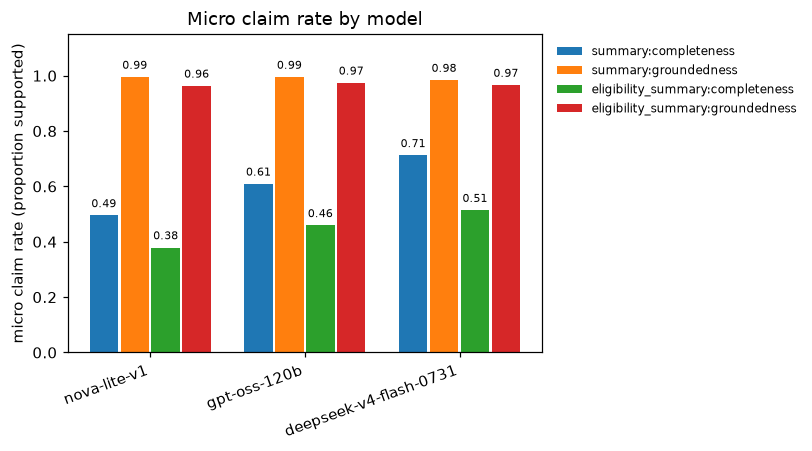

field:dimension                            summary:completeness  \
rate                                           micro claim rate   
openrouter/amazon/nova-lite-v1                            0.495   
openrouter/openai/gpt-oss-120b                            0.609   
openrouter/deepseek/deepseek-v4-flash-0731                0.712   

field:dimension                                                          \
rate                                       macro claim rate record rate   
openrouter/amazon/nova-lite-v1                        0.484       0.112   
openrouter/openai/gpt-oss-120b                        0.613       0.139   
openrouter/deepseek/deepseek-v4-flash-0731            0.713       0.224   

field:dimension                            summary:groundedness  \
rate                                           micro claim rate   
openrouter/amazon/nova-lite-v1                            0.995   
openrouter/openai/gpt-oss-120b                            0.995   
openrouter/deepseek/deepseek-v4-flash-0731                0.984   

field:dimension                                                          \
rate                                       macro claim rate record rate   
openrouter/amazon/nova-lite-v1                        0.981       0.972   
openrouter/openai/gpt-oss-120b                        0.990       0.965   
openrouter/deepseek/deepseek-v4-flash-0731            0.973       0.908   

field:dimension                            eligibility_summary:completeness  \
rate                                                       micro claim rate   
openrouter/amazon/nova-lite-v1                                        0.379   
openrouter/openai/gpt-oss-120b                                        0.459   
openrouter/deepseek/deepseek-v4-flash-0731                            0.514   

field:dimension                                                          \
rate                                       macro claim rate record rate   
openrouter/amazon/nova-lite-v1                        0.380       0.028   
openrouter/openai/gpt-oss-120b                        0.486       0.041   
openrouter/deepseek/deepseek-v4-flash-0731            0.537       0.051   

field:dimension                            eligibility_summary:groundedness  \
rate                                                       micro claim rate   
openrouter/amazon/nova-lite-v1                                        0.963   
openrouter/openai/gpt-oss-120b                                        0.974   
openrouter/deepseek/deepseek-v4-flash-0731                            0.966   

field:dimension                                                          
rate                                       macro claim rate record rate  
openrouter/amazon/nova-lite-v1                        0.958       0.943  
openrouter/openai/gpt-oss-120b                        0.973       0.933  
openrouter/deepseek/deepseek-v4-flash-0731            0.972       0.933

In [6]:
run_dicts = [judgemod.read_verdict_file(p) for p in verdict_paths]
print(f"{len(run_dicts)} run verdict file(s) loaded from disk")

#: (rollup cell key, column label) for each of the three rates.
RATE_KEYS = [
    ("claim_rate", "micro claim rate"),
    ("claim_rate_macro", "macro claim rate"),
    ("record_rate", "record rate"),
]


def breakdown_chart(key, title):
    # Every run carries all four field:dimension keys, so no fallback is needed.
    grouped = jn.group_rollup(run_dicts, key=key)
    groups = sorted(grouped, key=lambda g: (len(g), g))  # stable, readable order

    micro_series = {
        fd: [rate_or_undefined(grouped[g][fd], "claim_rate") for g in groups]
        for fd in FIELD_DIM_ORDER
    }
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    labelled_group_bar(ax, [short_label(g) for g in groups], micro_series,
                       ylabel="micro claim rate (proportion supported)", title=title, ylim=(0, 1.15))
    fig.tight_layout()
    plt.show()

    table = pd.DataFrame(
        {
            (fd, label): [rate_or_undefined(grouped[g][fd], rate_key) for g in groups]
            for fd in FIELD_DIM_ORDER
            for rate_key, label in RATE_KEYS
        },
        index=groups,
    )
    table.columns = pd.MultiIndex.from_tuples(table.columns, names=["field:dimension", "rate"])
    return table


by_model_df = breakdown_chart("model", "Micro claim rate by model")
by_model_df

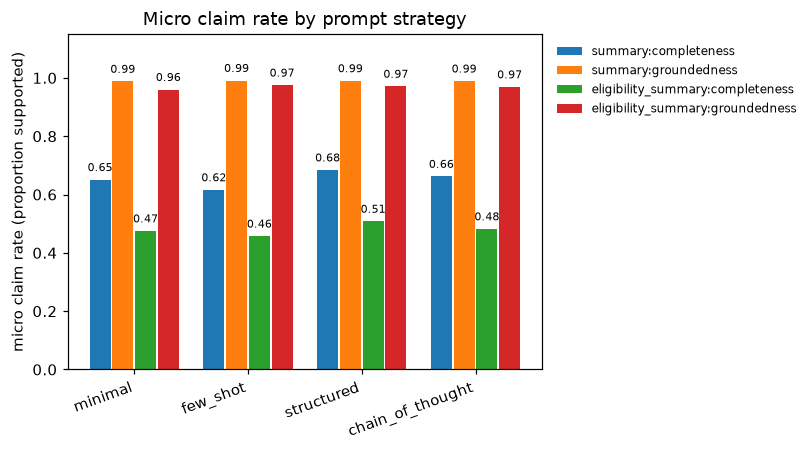

field:dimension  summary:completeness                               \
rate                 micro claim rate macro claim rate record rate   
minimal                         0.651            0.647       0.172   
few_shot                        0.616            0.618       0.144   
structured                      0.684            0.679       0.208   
chain_of_thought                0.662            0.663       0.201   

field:dimension  summary:groundedness                               \
rate                 micro claim rate macro claim rate record rate   
minimal                         0.988            0.978       0.932   
few_shot                        0.991            0.980       0.940   
structured                      0.990            0.984       0.942   
chain_of_thought                0.989            0.978       0.936   

field:dimension  eligibility_summary:completeness                   \
rate                             micro claim rate macro claim rate   
minimal                                     0.475            0.497   
few_shot                                    0.457            0.480   
structured                                  0.508            0.530   
chain_of_thought                            0.482            0.503   

field:dimension              eligibility_summary:groundedness  \
rate             record rate                 micro claim rate   
minimal                0.045                            0.960   
few_shot               0.030                            0.975   
structured             0.066                            0.971   
chain_of_thought       0.037                            0.969   

field:dimension                                
rate             macro claim rate record rate  
minimal                     0.962       0.929  
few_shot                    0.976       0.941  
structured                  0.971       0.932  
chain_of_thought            0.973       0.935

In [7]:
by_prompt_strategy_df = breakdown_chart("prompt_strategy", "Micro claim rate by prompt strategy")
by_prompt_strategy_df

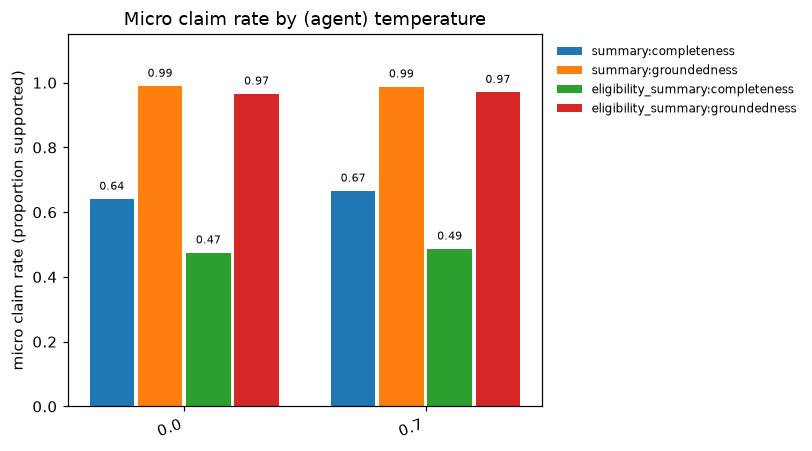

field:dimension summary:completeness                               \
rate                micro claim rate macro claim rate record rate   
0.0                            0.641            0.643       0.174   
0.7                            0.666            0.661       0.189   

field:dimension summary:groundedness                               \
rate                micro claim rate macro claim rate record rate   
0.0                            0.990            0.981       0.938   
0.7                            0.988            0.979       0.937   

field:dimension eligibility_summary:completeness                               \
rate                            micro claim rate macro claim rate record rate   
0.0                                        0.475            0.496       0.036   
0.7                                        0.487            0.510       0.054   

field:dimension eligibility_summary:groundedness                               
rate                            micro claim rate macro claim rate record rate  
0.0                                        0.966             0.97       0.937  
0.7                                        0.971             0.97       0.932

In [8]:
by_temperature_df = breakdown_chart("temperature", "Micro claim rate by (agent) temperature")
by_temperature_df

## Leaderboard

In [9]:
leaderboard_rows = jn.rank_configs(run_dicts)
leaderboard_df = pd.DataFrame([
    {
        "#": i,
        "config": r["config"],
        **{cell: (round(r["rates"][cell], 3) if r["rates"][cell] is not None else "undefined")
           for cell in jn.CELL_ORDER},
        "combined_macro": ("undefined" if r["combined_macro_undefined"] else round(r["combined_macro"], 3)),
        "n_cells": r["n_cells"],
        "n_claims": r["n_claims"],
    }
    for i, r in enumerate(leaderboard_rows, start=1)
]).set_index("#")
leaderboard_df

,config,summary:completeness,summary:groundedness,eligibility_summary:completeness,eligibility_summary:groundedness,combined_macro,n_cells,n_claims
#,,,,,,,,
1,openrouter/deepseek/deepseek-v4-flash-0731 | s...,0.768,0.977,0.591,0.966,0.825,4,11546
2,openrouter/deepseek/deepseek-v4-flash-0731 | s...,0.748,0.974,0.556,0.978,0.814,4,11045
3,openrouter/deepseek/deepseek-v4-flash-0731 | m...,0.721,0.970,0.548,0.967,0.802,4,11684
4,openrouter/deepseek/deepseek-v4-flash-0731 | c...,0.710,0.971,0.538,0.977,0.799,4,11725
5,openrouter/deepseek/deepseek-v4-flash-0731 | f...,0.687,0.978,0.525,0.971,0.790,4,11638
6,openrouter/deepseek/deepseek-v4-flash-0731 | m...,0.700,0.971,0.519,0.969,0.790,4,10554
7,openrouter/deepseek/deepseek-v4-flash-0731 | c...,0.701,0.965,0.510,0.970,0.786,4,10506
8,openrouter/deepseek/deepseek-v4-flash-0731 | f...,0.668,0.977,0.499,0.974,0.779,4,9666
9,openrouter/openai/gpt-oss-120b | chain_of_thou...,0.640,0.994,0.496,0.972,0.776,4,6938


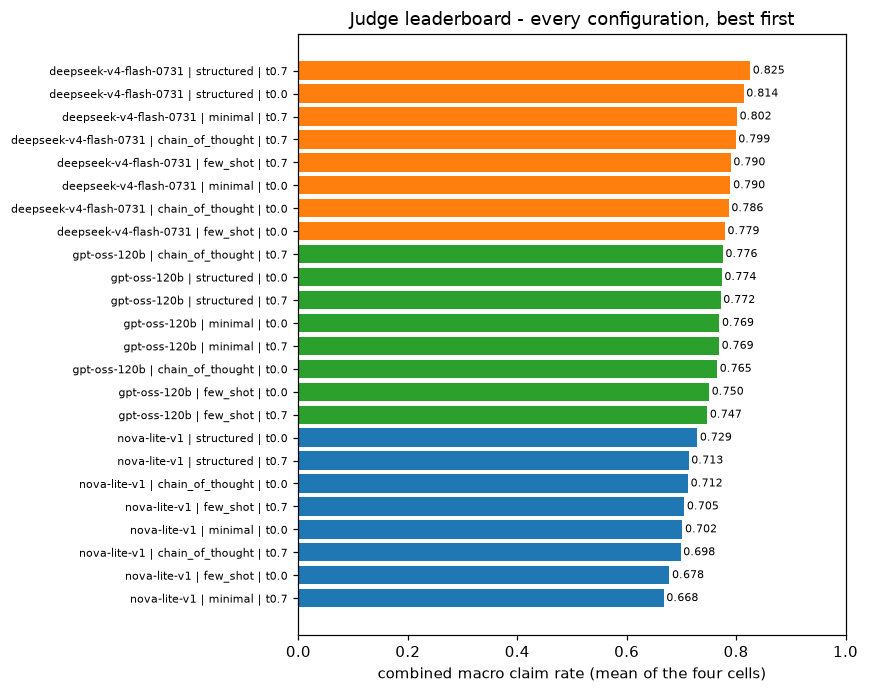

In [10]:
fig, ax = plt.subplots(figsize=(8.0, 6.4))
labels = [short_label(r["config"]) for r in leaderboard_rows][::-1]
values = [(0.0 if r["combined_macro_undefined"] else r["combined_macro"]) for r in leaderboard_rows][::-1]
ax.barh(labels, values, color=[model_color(lb) for lb in labels])
for y, v in enumerate(values):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=7.5)
ax.set_xlabel("combined macro claim rate (mean of the four cells)")
ax.set_title("Judge leaderboard - every configuration, best first")
ax.set_xlim(0, 1.0)
ax.tick_params(axis="y", labelsize=7.5)
fig.tight_layout()
plt.show()

### Per-cell winners

In [11]:
best_cells = jn.best_config_per_cell(run_dicts)
best_cells_df = pd.DataFrame([
    {
        "field:dimension": cell,
        "best config": best_cells[cell]["config"] if not best_cells[cell]["undefined"] else "undefined",
        "macro claim rate": ("undefined" if best_cells[cell]["undefined"] else round(best_cells[cell]["rate"], 3)),
    }
    for cell in jn.CELL_ORDER
]).set_index("field:dimension")
best_cells_df

,best config,macro claim rate
field:dimension,,
summary:completeness,openrouter/deepseek/deepseek-v4-flash-0731 | s...,0.768
summary:groundedness,openrouter/amazon/nova-lite-v1 | structured | ...,0.999
eligibility_summary:completeness,openrouter/deepseek/deepseek-v4-flash-0731 | s...,0.591
eligibility_summary:groundedness,openrouter/amazon/nova-lite-v1 | chain_of_thou...,1.000


### Judge rank against detection F1

In [12]:
agreement_rows = jn.rank_agreement_with_f1(run_dicts)
rank_agreement_df = pd.DataFrame([
    {
        "config": r["config"].replace("openrouter/", ""),
        "F1 rank": r["f1_rank"], "judge rank": r["judge_rank"],
        "macro F1": round(r["macro_f1"], 3) if r["macro_f1"] is not None else "undefined",
        "judge combined": (round(r["judge_combined_macro"], 3)
                           if r["judge_combined_macro"] is not None else "undefined"),
        "rank shift": (abs(r["f1_rank"] - r["judge_rank"])
                       if (r["f1_rank"] is not None and r["judge_rank"] is not None) else "—"),
    }
    for r in agreement_rows
]).set_index("config")
rank_agreement_df

,F1 rank,judge rank,macro F1,judge combined,rank shift
config,,,,,
deepseek/deepseek-v4-flash-0731 | few_shot | t0.7,1,5,0.793,0.790,4
deepseek/deepseek-v4-flash-0731 | minimal | t0.7,2,3,0.786,0.802,1
deepseek/deepseek-v4-flash-0731 | structured | t0.7,3,1,0.784,0.825,2
deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.7,4,4,0.768,0.799,0
deepseek/deepseek-v4-flash-0731 | chain_of_thought | t0.0,5,7,0.752,0.786,2
deepseek/deepseek-v4-flash-0731 | structured | t0.0,6,2,0.749,0.814,4
deepseek/deepseek-v4-flash-0731 | few_shot | t0.0,7,8,0.722,0.779,1
deepseek/deepseek-v4-flash-0731 | minimal | t0.0,8,6,0.710,0.790,2
openai/gpt-oss-120b | chain_of_thought | t0.7,9,9,0.566,0.776,0


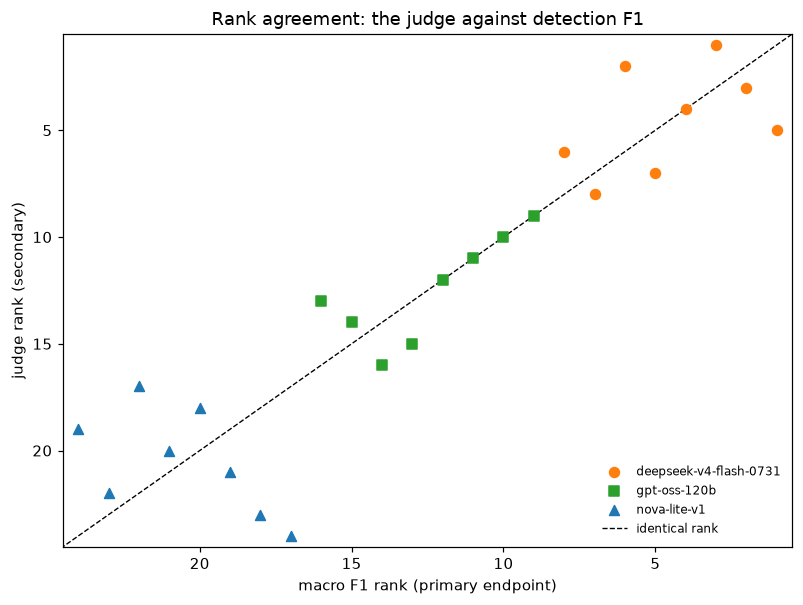

In [13]:
fig, ax = plt.subplots(figsize=(7.4, 5.6))
pairs = [(r["f1_rank"], r["judge_rank"], r["config"]) for r in agreement_rows
         if r["f1_rank"] is not None and r["judge_rank"] is not None]
seen = set()
for f1r, jr, label in pairs:
    model = ("deepseek-v4-flash-0731" if "deepseek" in label
             else "gpt-oss-120b" if "gpt-oss" in label else "nova-lite-v1")
    marker = "o" if "deepseek" in label else ("s" if "gpt-oss" in label else "^")
    ax.scatter(f1r, jr, s=42, color=model_color(label), marker=marker, zorder=3,
               label=None if model in seen else model)
    seen.add(model)
lo, hi = 0.5, len(pairs) + 0.5
ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=0.9, color="black", zorder=1,
        label="identical rank")
ax.set_xlabel("macro F1 rank (primary endpoint)")
ax.set_ylabel("judge rank (secondary)")
ax.set_title("Rank agreement: the judge against detection F1")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.invert_xaxis(); ax.invert_yaxis()
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

## Which kinds of claim go missing

In [14]:
ct = jn.claim_type_breakdown(run_dicts)
claim_type_df = pd.DataFrame([
    {
        "claim_type": t,
        **{
            f"{d} n": ct[t][d]["n_claims"] for d in judgemod.DIMENSIONS
        },
        **{
            f"{d} rate": ("undefined" if ct[t][d]["support_rate_undefined"]
                          else round(ct[t][d]["support_rate"], 3))
            for d in judgemod.DIMENSIONS
        },
    }
    for t in judgemod.CLAIM_TYPES
]).set_index("claim_type")
claim_type_df

,completeness n,groundedness n,completeness rate,groundedness rate
claim_type,,,,
eligibility,37033,36856,0.581,0.978
deadline,1458,8896,0.567,0.985
amount,6578,8428,0.453,0.978
purpose,17516,19241,0.658,0.986
process,2379,9540,0.334,0.993
other,6912,10603,0.409,0.996


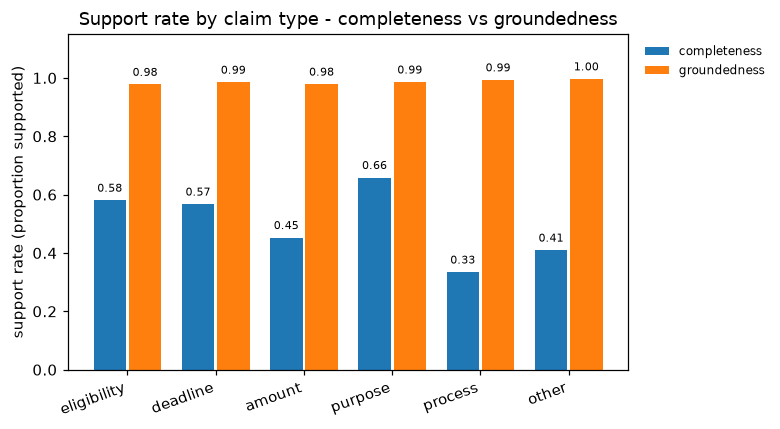

In [15]:
fig, ax = plt.subplots(figsize=(7.2, 4.0))
types = list(judgemod.CLAIM_TYPES)
series = {
    d: [("undefined" if ct[t][d]["support_rate_undefined"] else ct[t][d]["support_rate"])
        for t in types]
    for d in judgemod.DIMENSIONS
}
labelled_group_bar(
    ax, types, series,
    ylabel="support rate (proportion supported)",
    title="Support rate by claim type - completeness vs groundedness", ylim=(0, 1.15),
)
fig.tight_layout()
plt.show()

## By funder

In [16]:
by_funder = rollup["by_funder"]


def funder_rate(cells, cell_key):
    cell = cells.get(cell_key)
    if cell is None or cell["claim_rate_macro_undefined"]:
        return "undefined"
    return round(cell["claim_rate_macro"], 3)


by_funder_df = pd.DataFrame([
    {"funder": funder, **{cell: funder_rate(cells, cell) for cell in jn.CELL_ORDER}}
    for funder, cells in sorted(by_funder.items())
]).set_index("funder")
by_funder_df

,summary:completeness,summary:groundedness,eligibility_summary:completeness,eligibility_summary:groundedness
funder,,,,
British Ecological Society,0.739,0.994,0.447,0.961
Cara (Council for At-Risk Academics),0.704,0.945,0.477,0.959
Carnegie Trust for the Universities of Scotland,0.751,0.976,0.563,0.953
Garfield Weston Foundation,0.772,0.570,0.520,0.582
Great Britain Sasakawa Foundation,0.647,0.998,0.469,0.990
Henry Moore Foundation,0.653,0.956,0.626,0.987
Nuffield Farming Scholarships Trust,0.697,0.929,0.738,0.903
Nuffield Foundation,0.574,0.992,0.517,0.972
Paul Mellon Centre for Studies in British Art,0.668,0.979,0.466,0.995


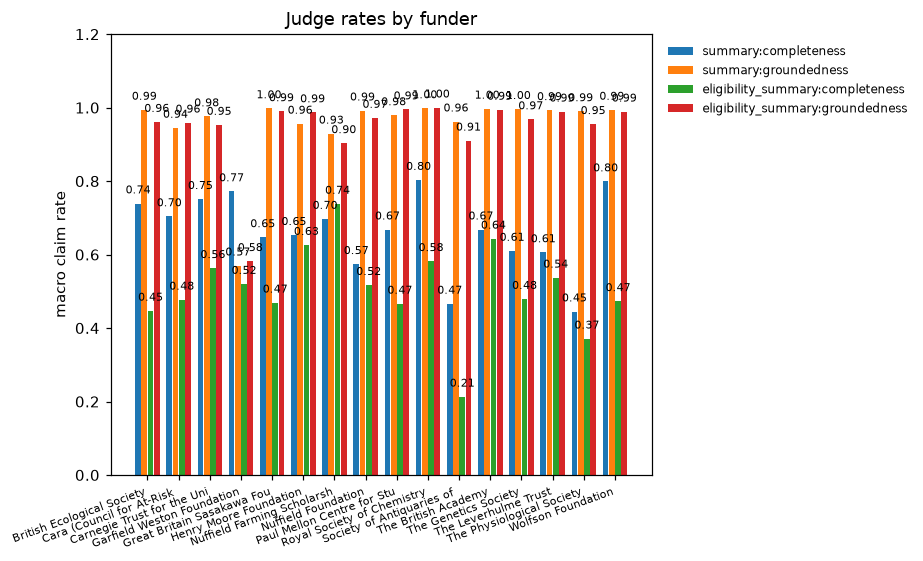

In [17]:
fig, ax = plt.subplots(figsize=(8.4, 5.2))
funders_sorted = sorted(by_funder)
series = {cell: [funder_rate(by_funder[f], cell) for f in funders_sorted] for cell in jn.CELL_ORDER}
labelled_group_bar(
    ax, [f[:26] for f in funders_sorted], series,
    ylabel="macro claim rate", title="Judge rates by funder", ylim=(0, 1.2),
)
ax.tick_params(axis="x", labelsize=7)
fig.tight_layout()
plt.show()

## Exclusions

In [18]:
ledger = rollup["exclusion_ledger"]
reason_counts = jn.exclusion_reason_counts(ledger)
print(f"{len(ledger)} excluded record(s) total")
reason_counts_df = pd.Series(reason_counts, name="n").sort_values(ascending=False).to_frame()
reason_counts_df

2573 excluded record(s) total


,n
judge_parse_failure,1407
field_empty,1127
unresolvable_source,38
judge_call_failure,1


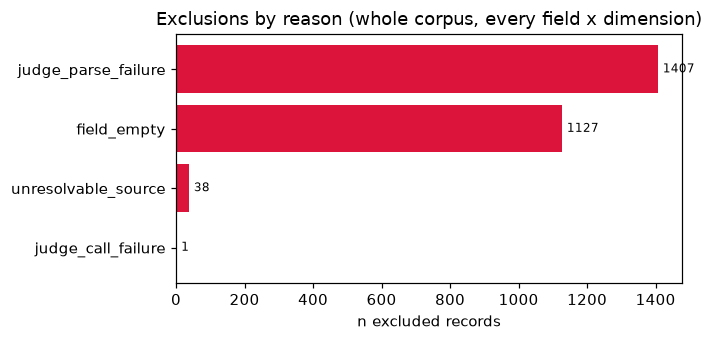

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
labels = reason_counts_df.index.tolist()
values = reason_counts_df["n"].tolist()
ax.barh(labels, values, color="crimson")
for y, v in enumerate(values):
    ax.text(v + max(values) * 0.01, y, str(v), va="center", fontsize=8)
ax.set_xlabel("n excluded records")
ax.set_title("Exclusions by reason (whole corpus, every field x dimension)")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

In [20]:
ledger_df = pd.DataFrame(ledger)
excl_crosstab = pd.crosstab(
    [ledger_df["field"], ledger_df["dimension"]], ledger_df["reason"]
)
excl_crosstab

reason                            field_empty  judge_call_failure  \
field               dimension                                       
eligibility_summary completeness          271                   0   
                    groundedness          483                   1   
summary             completeness          123                   0   
                    groundedness          250                   0   

reason                            judge_parse_failure  unresolvable_source  
field               dimension                                               
eligibility_summary completeness                  447                    0  
                    groundedness                  315                   19  
summary             completeness                  323                    0  
                    groundedness                  322                   19

In [21]:
registry = load_registry(DEFAULT_REGISTRY_PATH)
ground_truth = load_ground_truth(DEFAULT_GROUND_TRUTH_DIR)
corpus_paths = sorted(GRID_ROOT.glob("*/*.json"))
print(f"{len(corpus_paths)} result file(s) in the corpus")

loaded = ja.load_judged_records(
    corpus_paths, ground_truth=ground_truth, registry=registry, snapshot_root=DEFAULT_SNAPSHOT_ROOT,
    results_root=RESULTS_ROOT, judge_config_hash=judge_config.config_hash,
)
print(f"{len(loaded.records)} judged record(s) loaded; "
      f"{len(loaded.skipped_unjudged)} skipped (unjudged), "
      f"{len(loaded.skipped_unlabelled_funder)} skipped (unlabelled funder), "
      f"{len(loaded.mismatched_funder)} mismatched, "
      f"{len(loaded.excluded_records)} excluded records")

all_claims = ja.explode_claims(loaded.records)
print(f"{len(all_claims)} claim(s) exploded from those records")

1920 result file(s) in the corpus


22001 judged record(s) loaded; 0 skipped (unjudged), 0 skipped (unlabelled funder), 0 mismatched, 1408 excluded records


165440 claim(s) exploded from those records


## Agreement with the human review

A person checked 200 judge verdicts by hand (`data/checks/judge_check.csv`), and this compares their yes/no answers with the judge's.

In [22]:
check_df = pd.read_csv(REPO_ROOT / "data" / "checks" / "judge_check.csv")
check_df["agree"] = check_df["judge_verdict"] == check_df["human_verdict"]
n_agree, n = int(check_df["agree"].sum()), len(check_df)
print(f"overall: {n_agree}/{n} = {n_agree / n:.1%}")
for dim, grp in check_df.groupby("dimension"):
    print(f"{dim}: {int(grp['agree'].sum())}/{len(grp)} = {grp['agree'].mean():.1%}")

overall: 186/200 = 93.0%
completeness: 95/100 = 95.0%
groundedness: 91/100 = 91.0%


In [23]:
pd.crosstab(check_df["human_verdict"], check_df["judge_verdict"], rownames=["human"], colnames=["judge"], margins=True)

judge,no,yes,All
human,,,
no,88,2,90
yes,12,98,110
All,100,100,200


## Worst unsupported claims

In [28]:
worst = jn.worst_unsupported_claims(all_claims, n=15)
worst_df = pd.DataFrame([
    {
        "field": c.field, "dimension": c.dimension, "funder": c.funder, "opportunity_id": c.opportunity_id,
        "claim_text": c.claim_text, "claim_type": c.claim_type,
        "extracted_text": (c.extracted_text[:160] + "…") if len(c.extracted_text) > 160 else c.extracted_text,
        "comparison_reference": (c.comparison_display[:80] + "…") if len(c.comparison_display) > 80 else c.comparison_display,
    }
    for c in worst
])
pd.set_option("display.max_colwidth", 200)
worst_df

,field,dimension,funder,opportunity_id,claim_text,claim_type,extracted_text,comparison_reference
0,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarship,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or be in a position to influence these industries.",eligibility,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or are in a position to influence these industries. Appl…",data/snapshots/nuffield-farming/2026-08-21/site/www.nuffieldscholar.org/scholars…
1,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarship,Applicants must be aged between 25 and 45 years.,eligibility,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or are in a position to influence these industries. Appl…",data/snapshots/nuffield-farming/2026-08-21/site/www.nuffieldscholar.org/scholars…
2,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarship,The upper age limit is 45 on July 31st in the year of application.,eligibility,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or are in a position to influence these industries. Appl…",data/snapshots/nuffield-farming/2026-08-21/site/www.nuffieldscholar.org/scholars…
3,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarship,There is no requirement for academic qualifications.,eligibility,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or are in a position to influence these industries. Appl…",data/snapshots/nuffield-farming/2026-08-21/site/www.nuffieldscholar.org/scholars…
4,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarship,Applicants must be resident in the UK.,eligibility,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or are in a position to influence these industries. Appl…",data/snapshots/nuffield-farming/2026-08-21/site/www.nuffieldscholar.org/scholars…
5,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarship,Applicants must hold a UK passport or be working directly for UK agriculture.,eligibility,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or are in a position to influence these industries. Appl…",data/snapshots/nuffield-farming/2026-08-21/site/www.nuffieldscholar.org/scholars…
6,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarships,The opportunity is open to UK-based researchers.,eligibility,"Open to UK-based researchers interested in farming, food, horticulture, forestry or any other countryside and ancillary industry.",data/snapshots/nuffield-farming/2026-08-21/site/www.nuffieldscholar.org/scholars…
7,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarships,"Applicants must work within or be in a position to influence the farming, food, horticultural, forestry, rural, and associated industries.",eligibility,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or are in a position to influence these industries. Appl…",data/snapshots/nuffield-farming/2026-08-21/site/www.nuffieldscholar.org/scholars…
8,eligibility_summary,groundedness,Nuffield Farming Scholarships Trust,2027-Nuffield-Farming-Scholarships,"Applicants must work within or be in a position to influence the farming, food, horticultural, forestry, rural, and associated industries.",eligibility,"Applicants must work within the farming, food, horticultural, forestry, rural and associated industries or are in a position to influenc